# 木とハッシュ：形と散らばりを見る

第7回では，引きながら書き足せる構造を 2 つの方向から作った。
木（順序を保つ）とハッシュ表（順序を捨てる）である。

ここで確かめるのは次の 4 つである。

1. 二分探索木の高さは **入れる順序**で決まる
2. 高さがそのまま探索の時間に出る
3. ハッシュ関数の $m$ の選び方ひとつで，散らばりがまるで変わる
4. 衝突は思うよりずっと早く起きる。そして **かたまり** は余分な手間を生む

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

## 二分探索木を作る

擬似コードをそのまま写す。
ただし **再帰ではなく繰り返しで**書く。
一列に崩れた木を扱うので，再帰だと Python の上限（既定 1000 段）に当たるからである。
これも領域計算量 $O(h)$ が現実の制約として出てくる例である。

In [2]:
class Node:
    """二分探索木の節点。"""

    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None


class BST:
    """二分探索木。繰り返しで書いてある。"""

    def __init__(self):
        self.root = None
        self.size = 0

    def insert(self, key):
        """すでにある鍵は入れない。"""
        if self.root is None:
            self.root = Node(key)
            self.size = 1
            return
        x = self.root
        while True:
            if key < x.key:
                if x.left is None:
                    x.left = Node(key)
                    self.size += 1
                    return
                x = x.left
            elif key > x.key:
                if x.right is None:
                    x.right = Node(key)
                    self.size += 1
                    return
                x = x.right
            else:
                return                      # 重複

    def search(self, key):
        """(見つかったか, 比べた回数) を返す。"""
        x, count = self.root, 0
        while x is not None:
            count += 1
            if key == x.key:
                return True, count
            x = x.left if key < x.key else x.right
        return False, count

    def height(self):
        """辺の数で測った高さ。空の木は -1。レベル順に数える。"""
        from collections import deque
        if self.root is None:
            return -1
        h, q = -1, deque([self.root])
        while q:
            h += 1
            for _ in range(len(q)):
                x = q.popleft()
                if x.left:
                    q.append(x.left)
                if x.right:
                    q.append(x.right)
        return h

    def avg_depth(self):
        """節点 1 つあたりの平均の深さ。探索の平均の比較回数にあたる。"""
        from collections import deque
        if self.root is None:
            return 0.0
        total, count, q = 0, 0, deque([(self.root, 0)])
        while q:
            x, d = q.popleft()
            total += d
            count += 1
            if x.left:
                q.append((x.left, d + 1))
            if x.right:
                q.append((x.right, d + 1))
        return total / count

    def inorder(self):
        """間順。自前のスタックでたどる。"""
        out, stack, x = [], [], self.root
        while stack or x is not None:
            while x is not None:
                stack.append(x)
                x = x.left
            x = stack.pop()
            out.append(x.key)
            x = x.right
        return out


t = BST()
for k in (50, 30, 70, 20, 40, 60, 80):
    t.insert(k)

print("間順:", t.inorder())
print("高さ:", t.height())
print("60 を探す:", t.search(60))
print("65 を探す:", t.search(65))

間順: [20, 30, 40, 50, 60, 70, 80]
高さ: 2
60 を探す: (True, 3)
65 を探す: (False, 3)


**間順にたどると昇順に並ぶ。** 条件そのものである。

整列のつもりで書いたわけではないのに，順に並んで出てくる。
ハッシュ表にはこれができない，というのが今回の分かれ目であった。

## 挿入順で高さが変わる

同じ値の集まりでも，入れる順序で木の形は大きく変わる。
でたらめな順序と昇順で比べてみる。

In [3]:
import math
import random

random.seed(0)

print(f"{'n':>7}{'高さ':>10}{'高さ(昇順)':>9}{'平均の深さ':>12}"
      f"{'1.39 log2 n':>13}{'2.99 log2 n':>13}")
for n in (100, 1000, 10000, 100000):
    keys = list(range(n))

    shuffled = keys[:]
    random.shuffle(shuffled)
    t_rand = BST()
    for k in shuffled:
        t_rand.insert(k)

    t_sorted = BST()
    for k in keys:
        t_sorted.insert(k)

    print(f"{n:>7}{t_rand.height():>10}{t_sorted.height():>9}"
          f"{t_rand.avg_depth():>12.1f}"
          f"{1.39 * math.log2(n):>13.1f}{2.99 * math.log2(n):>13.1f}")

      n        高さ   高さ(昇順)       平均の深さ  1.39 log2 n  2.99 log2 n
    100        12       99         6.2          9.2         19.9
   1000        19      999        10.3         13.9         29.8


  10000        31     9999        15.7         18.5         39.7


 100000        39    99999        19.8         23.1         49.7


2 つの量を区別しておきたい。

- **平均の深さ** …… 節点 1 つあたりの深さ。探索の平均の比較回数にあたる。
  漸近的に $2 \ln n \approx 1.39 \log_2 n$
- **高さ** …… いちばん深い葉までの距離。最悪の比較回数にあたる。
  漸近的に $4.31 \ln n \approx 2.99 \log_2 n$

どちらの実測も，対応する式より少し小さい。
漸近式には $-O(\log \log n)$ などの引き算が付くので，
この程度の $n$ ではまだ届かない。
**どちらも $\log n$ に比例する**というのが肝心なところである。

昇順は $n - 1$，すなわち**一列**である。
$n = 10$ 万なら高さ 99999 で，線形リストとまったく同じ形になっている。

ここが二分探索木の弱点であった。
**最悪の形は，いちばんありふれた入力（整列済み）から生まれる。**

### 高さの分布

でたらめ順に入れたときの高さが，どれくらいばらつくかも見ておく。

In [4]:
random.seed(1)
n = 2000
heights = []
for _ in range(200):
    ks = list(range(n))
    random.shuffle(ks)
    b = BST()
    for k in ks:
        b.insert(k)
    heights.append(b.height())

print(f"n = {n}")
print(f"  最小 {min(heights)} / 平均 {sum(heights) / len(heights):.1f} "
      f"/ 最大 {max(heights)}")
print(f"  漸近の目安 2.99 log2 n = {2.99 * math.log2(n):.1f}")
print(f"  （AVL 木なら必ず {math.floor(1.44 * math.log2(n + 2))} 以下）")

n = 2000
  最小 21 / 平均 23.9 / 最大 30
  漸近の目安 2.99 log2 n = 32.8
  （AVL 木なら必ず 15 以下）


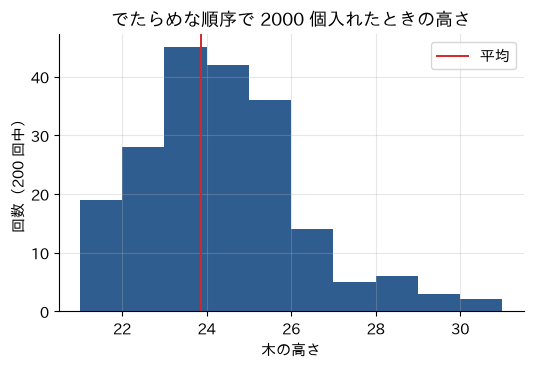

In [5]:
fig, ax = plt.subplots()
ax.hist(heights, bins=range(min(heights), max(heights) + 2), color="#2f5d8f")
ax.axvline(sum(heights) / len(heights), color="#d62728", lw=1.4,
           label="平均")
ax.set_xlabel("木の高さ")
ax.set_ylabel("回数（200 回中）")
ax.set_title(f"でたらめな順序で {n} 個入れたときの高さ")
ax.legend()
plt.show()

狭い範囲に集まっている。
でたらめに入れるかぎり，極端に高い木はまず出ない。
AVL 木の上限（$1.44 \log_2 (n+2)$）は超えているが，それでも $n-1$ にはほど遠い。

しかしこれは **平均の話**であって，保証ではない。
入れる順序を選べない場面では，この分布のどこに落ちるかを決められない。
だから形を管理する（平衡木にする）のであった。

## 高さは時間に出る

高さの違いが探索の時間にどう出るかを測る。

In [6]:
import time

n = 20000
keys = list(range(n))

random.seed(2)
shuffled = keys[:]
random.shuffle(shuffled)

t_rand = BST()
for k in shuffled:
    t_rand.insert(k)

t_sorted = BST()
for k in keys:
    t_sorted.insert(k)

d = {k: k for k in keys}

random.seed(3)
probe = [random.randrange(n) for _ in range(2000)]

def timeit(f):
    t0 = time.perf_counter()
    for k in probe:
        f(k)
    return (time.perf_counter() - t0) / len(probe) * 1e6      # マイクロ秒

print(f"木の高さ: でたらめ順 {t_rand.height()} / 昇順 {t_sorted.height()}")
print()
print(f"{'探索 1 回あたり':<22}{'時間 (us)':>12}{'比べた回数':>12}")
print(f"{'二分探索木（でたらめ順）':<22}{timeit(lambda k: t_rand.search(k)):>12.2f}"
      f"{sum(t_rand.search(k)[1] for k in probe) / len(probe):>12.1f}")
print(f"{'二分探索木（昇順）':<22}{timeit(lambda k: t_sorted.search(k)):>12.2f}"
      f"{sum(t_sorted.search(k)[1] for k in probe) / len(probe):>12.1f}")
print(f"{'dict（ハッシュ表）':<22}{timeit(lambda k: k in d):>12.2f}{'1':>12}")

木の高さ: でたらめ順 34 / 昇順 19999

探索 1 回あたり                  時間 (us)       比べた回数
二分探索木（でたらめ順）                  1.33        18.5


二分探索木（昇順）                   500.04     10152.8
dict（ハッシュ表）                   0.22           1


高さがそのまま比較の回数になり，時間になっている。
`dict` は木をたどらないので桁違いに速い。

ただし `dict` が返せるのは「あるか／ないか」だけである。
範囲や順序が要るなら木に戻るしかない。

## ハッシュ関数の散らばり

除算法 $h(k) = k \bmod m$ で，$m$ の選び方がどれだけ効くかを見る。

鍵には規則性のあるもの，たとえば学籍番号のような
**末尾だけが動く数**を使う。

In [7]:
from collections import Counter

# 2026 年度入学・学部コード 12・通し番号、のような形の鍵
student_ids = [20261200000 + 10 * i for i in range(3000)]

print("鍵の例:", student_ids[:4])

for m in (1000, 997):
    buckets = Counter(k % m for k in student_ids)
    used = len(buckets)
    longest = max(buckets.values())
    print(f"\nm = {m}")
    print(f"  使われた場所: {used} / {m}")
    print(f"  いちばん長い鎖: {longest} 個")
    print(f"  平均の鎖の長さ（使われた場所だけ）: "
          f"{len(student_ids) / used:.1f}")

鍵の例: [20261200000, 20261200010, 20261200020, 20261200030]

m = 1000
  使われた場所: 100 / 1000
  いちばん長い鎖: 30 個
  平均の鎖の長さ（使われた場所だけ）: 30.0

m = 997
  使われた場所: 997 / 997
  いちばん長い鎖: 4 個
  平均の鎖の長さ（使われた場所だけ）: 3.0


$m = 1000$ では，使われる場所が**ごく一部に偏る**。
鍵の末尾が 10 の倍数なので，$k \bmod 1000$ の取りうる値が 100 通りしかないからである。

$m = 997$（素数）にすると，ほぼすべての場所が使われる。

この差を図で見る。

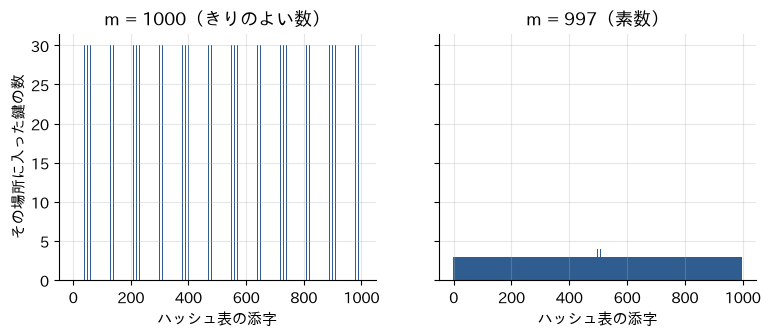

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2), sharey=True)
for ax, m in zip(axes, (1000, 997)):
    buckets = Counter(k % m for k in student_ids)
    sizes = [buckets.get(i, 0) for i in range(m)]
    ax.bar(range(m), sizes, width=1.0, color="#2f5d8f")
    ax.set_title(f"m = {m}" + ("（きりのよい数）" if m == 1000 else "（素数）"))
    ax.set_xlabel("ハッシュ表の添字")
axes[0].set_ylabel("その場所に入った鍵の数")
plt.show()

左は櫛の歯のように抜けていて，入ったところには何個も積み上がっている。
右はほぼ平らである。

**$m$ を 3 だけ変えただけ**で，探索の手間が何倍も違ってくる。
「散らばればよい」という条件は，思っているより繊細である。

## 衝突はいつ起きるか

誕生日のパラドックスを確かめる。
$m = 365$ の表に鍵を入れていき，何個目で衝突するかを数える。

In [9]:
def first_collision(m, rng):
    """空の表に入れていって、最初に衝突するまでに入れた鍵の数。"""
    seen = set()
    count = 0
    while True:
        count += 1
        h = rng.randrange(m)
        if h in seen:
            return count
        seen.add(h)


rng = random.Random(4)
m = 365
trials = [first_collision(m, rng) for _ in range(20000)]

for n in (10, 20, 23, 30, 50):
    p = sum(1 for t in trials if t <= n) / len(trials)
    print(f"{n:3d} 個入れた時点で衝突している割合: {p:6.1%}"
          f"   （表の {n / m:4.1%} しか埋まっていない）")

 10 個入れた時点で衝突している割合:  11.9%   （表の 2.7% しか埋まっていない）
 20 個入れた時点で衝突している割合:  41.8%   （表の 5.5% しか埋まっていない）
 23 個入れた時点で衝突している割合:  51.0%   （表の 6.3% しか埋まっていない）
 30 個入れた時点で衝突している割合:  70.4%   （表の 8.2% しか埋まっていない）
 50 個入れた時点で衝突している割合:  97.0%   （表の 13.7% しか埋まっていない）


23 個で 50 % を超える。表はまだ 6 % しか埋まっていない。

**衝突は例外ではない。** だから衝突処理はハッシュ法の中核なのであった。

## かたまりの影響

線形探索法（開番地法）では，ぶつかったら隣を見る。
その結果，埋まったところの隣が埋まりやすくなり，塊が育つ。

比べるために，**ぶつかったらばらばらな場所へ飛ぶ**方式も書いてみる
（二重ハッシュ法という）。
同じ負荷率で，探すのにいくつの場所を見るかを数える。

In [10]:
M = 1009          # 素数にしておく


def build(keys, mode):
    """開番地法で表を作る。mode は 'linear' か 'double'。"""
    table = [None] * M
    for k in keys:
        h = k % M
        step = 1 if mode == "linear" else 1 + (k // M) % (M - 1)
        i = 0
        while table[(h + i * step) % M] is not None:
            i += 1
        table[(h + i * step) % M] = k
    return table


def probes(table, keys, mode):
    """成功探索で見た場所の数の平均。"""
    total = 0
    for k in keys:
        h = k % M
        step = 1 if mode == "linear" else 1 + (k // M) % (M - 1)
        i = 0
        while table[(h + i * step) % M] != k:
            i += 1
        total += i + 1
    return total / len(keys)


rng = random.Random(5)
print(f"{'負荷率':>8}{'線形探索法':>14}{'二重ハッシュ法':>16}")
for alpha in (0.3, 0.5, 0.7, 0.9, 0.95):
    n = int(M * alpha)
    keys = rng.sample(range(10**7), n)
    row = [probes(build(keys, mode), keys, mode)
           for mode in ("linear", "double")]
    print(f"{alpha:>8.2f}{row[0]:>14.2f}{row[1]:>16.2f}")

     負荷率         線形探索法         二重ハッシュ法
    0.30          1.23            1.17
    0.50          1.53            1.40
    0.70          2.18            1.77
    0.90          4.72            2.54
    0.95          7.83            3.15


負荷率が低いうちはどちらも 1 回で見つかるが，
表が埋まってくると **線形探索法のほうがはっきり不利**になる。
塊のぶんだけ余計に歩かされているからである。

実用で $\alpha$ を 0.5 から 0.75 あたりに保つのは，この急な立ち上がりを避けるためである。

::: 線形探索法にも利点はある。
添字が連続しているので，計算機のキャッシュに乗りやすく，
1 回の探査そのものが速い。
回数が増えても，実時間では負けないことがある。
:::

## `dict` の順序

最後に，Python の `dict` が何を覚えていて，何を覚えていないかを確かめる。

In [11]:
d = {}
for k in (50, 10, 30, 20, 40):
    d[k] = k * k

print("list(d)   :", list(d))          # 挿入した順
print("sorted(d) :", sorted(d))        # 並べ替えが要る

# 木なら、間順にたどるだけで昇順に出てくる
t = BST()
for k in (50, 10, 30, 20, 40):
    t.insert(k)
print("木の間順  :", t.inorder())

list(d)   : [50, 10, 30, 20, 40]
sorted(d) : [10, 20, 30, 40, 50]
木の間順  : [10, 20, 30, 40, 50]


`dict` が覚えているのは **挿入した順**であって，鍵の大小の順ではない。
小さい順に欲しければ `sorted()` が必要で，そこで $O(n \log n)$ かかる。

木なら間順にたどるだけで $O(n)$ である。
この差が，構造を選ぶときの判断材料になる。

## まとめ

- 二分探索木の高さは入れる順序で決まる。でたらめなら $\log n$ に比例，昇順なら $n-1$
- 「平均の深さ $1.39 \log_2 n$」と「高さ $2.99 \log_2 n$」は別物。混同しやすい
- 高さはそのまま比較の回数になり，時間になる
- 除算法では $m$ の選び方が効く。きりのよい数にすると鍵が偏る
- 衝突は早く起きる。$m = 365$ に 23 個で 50 %
- 線形探索法は塊ができるぶん，負荷率が上がると不利になる
- `dict` は挿入順しか覚えていない。順序が要るなら木